<center><h1>Kalawadia_Krish_HW5</h1></center>
<br>
<br>

Name: Krish Kalawadia
<br>
Github Username: KK10-USC
<br>
USC ID: 4532974788

## 1. Decision Trees as Interpretable Models

Import packages

In [31]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree


### (a) Obtain Data

Get the Accute Inamations Data Set

In [32]:
names_cols = ["temperature","nausea","lumbar_pain","urine_pushing","micturition_pains","burning_urethra","bladder_inflammation","nephritis"]

my_df = pd.read_csv("diagnosis.data",sep = "\t", encoding = "utf-16",names = names_cols)

my_df["temperature"] = my_df["temperature"].str.replace(",",".", regex = False).astype(float)

print(my_df)

     temperature nausea lumbar_pain urine_pushing micturition_pains  \
0           35.5     no         yes            no                no   
1           35.9     no          no           yes               yes   
2           35.9     no         yes            no                no   
3           36.0     no          no           yes               yes   
4           36.0     no         yes            no                no   
..           ...    ...         ...           ...               ...   
115         41.4     no         yes           yes                no   
116         41.5     no          no            no                no   
117         41.5    yes         yes            no               yes   
118         41.5     no         yes           yes                no   
119         41.5     no         yes           yes                no   

    burning_urethra bladder_inflammation nephritis  
0                no                   no        no  
1               yes                  yes 

### (b) Build a decision tree

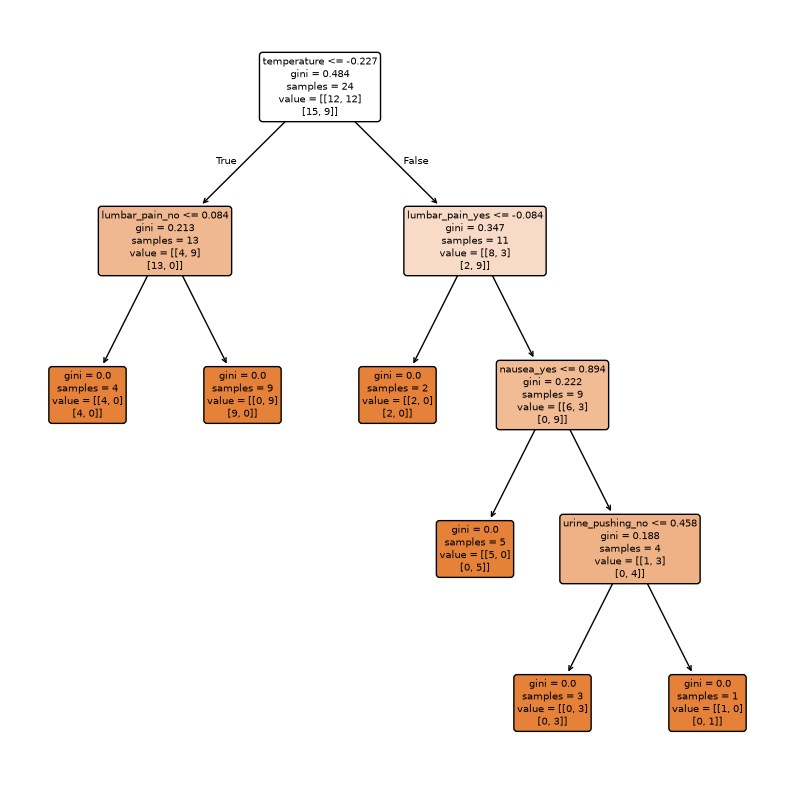

In [33]:
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

#Creating the target and feature dataset
y = my_df[["bladder_inflammation","nephritis"]]
x = my_df.drop(columns = ["bladder_inflammation","nephritis"])


#Creating the training and testing split and scaling the data
x_test,x_train,y_test,y_train = train_test_split(x,y,test_size = 0.2, random_state = 42)

#Encoding the columns for the tree
x_train_encoded = pd.get_dummies(x_train)
x_test_encoded = pd.get_dummies(x_test).reindex(columns = x_train_encoded.columns,fill_value = 0)

my_scaler = StandardScaler()
x_train_scaled = my_scaler.fit_transform(x_train_encoded)
x_test_scaled = my_scaler.transform(x_test_encoded)

#Building the tree
my_tree = DecisionTreeClassifier()
my_tree.fit(x_train_scaled,y_train)

#Plotting the tree
plt.figure(figsize=(10,10))
plot_tree(my_tree,feature_names = list(x_train_encoded.columns),class_names = my_tree.classes_,filled = True, rounded = True)
plt.show()


### (c) Convert the decision rules

In [34]:
from sklearn.tree import export_text
my_tree_rules = export_text(my_tree,feature_names = list(x_train_encoded.columns))
print(my_tree_rules)

|--- temperature <= -0.23
|   |--- lumbar_pain_no <= 0.08
|   |   |--- class: 0
|   |--- lumbar_pain_no >  0.08
|   |   |--- class: 1
|--- temperature >  -0.23
|   |--- lumbar_pain_yes <= -0.08
|   |   |--- class: 0
|   |--- lumbar_pain_yes >  -0.08
|   |   |--- nausea_yes <= 0.89
|   |   |   |--- class: 0
|   |   |--- nausea_yes >  0.89
|   |   |   |--- urine_pushing_no <= 0.46
|   |   |   |   |--- class: 0
|   |   |   |--- urine_pushing_no >  0.46
|   |   |   |   |--- class: 0



### (d) Find minimal decision tree and Decision rules for it

In [37]:
from sklearn.metrics import accuracy_score

#creating a decision tree using CCP
minimal_tree = DecisionTreeClassifier(random_state = 42)
cost_path = minimal_tree.cost_complexity_pruning_path(x_train_encoded,y_train)
cost_alpha = cost_path.ccp_alphas
cost_impure= cost_path.impurities

#Training the decision tree based on alpha vals
list_of_trees = []
for c in cost_alpha:
    temp_tree = DecisionTreeClassifier(random_state = 42, ccp_alpha = c)
    temp_tree.fit(x_train_encoded,y_train)

    list_of_trees.append(temp_tree)

#Finding the minimal tree using test accuracy
test_scores = []
for l in list_of_trees:
    y_prediction = l.predict(x_test_scaled)
    score = accuracy_score(y_test,y_prediction)
    test_scores.append(score)

#Printing results
best_tree_index = test_scores.index(max(test_scores))
best_tree = list_of_trees[best_tree_index]
best_alpha = cost_alpha[best_tree_index]

print("Information about the Minimal Tree for this Dataset:\n")
print(f"Best Cost-Complexity Alpha:{best_alpha:.2f}")
print(f"Number of nodes for minimal tree: {best_tree.tree_.node_count}")
print(f"Max Depth of minimal tree: {best_tree.tree_.max_depth}")
    



C:\Users\ashka\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


ValueError: multiclass-multioutput is not supported

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [35]:
col_names = []
with open("communities.names") as n:
    for l in n:
        strip = l.strip()
        if strip.startswith("@attribute"):
            separate_parts = strip.split()
            if len(separate_parts) >= 2:
                col_names.append(separate_parts[1])

new_df = pd.read_csv("communities.data", na_values = "?", names = col_names)


print(new_df)


      state  county  community        communityname  fold  population  \
0         8     NaN        NaN         Lakewoodcity     1        0.19   
1        53     NaN        NaN          Tukwilacity     1        0.00   
2        24     NaN        NaN         Aberdeentown     1        0.00   
3        34     5.0    81440.0  Willingborotownship     1        0.04   
4        42    95.0     6096.0    Bethlehemtownship     1        0.01   
...     ...     ...        ...                  ...   ...         ...   
1989     12     NaN        NaN    TempleTerracecity    10        0.01   
1990      6     NaN        NaN          Seasidecity    10        0.05   
1991      9     9.0    80070.0        Waterburytown    10        0.16   
1992     25    17.0    72600.0          Walthamcity    10        0.08   
1993      6     NaN        NaN          Ontariocity    10        0.20   

      householdsize  racepctblack  racePctWhite  racePctAsian  ...  LandArea  \
0              0.33          0.02          

### (b) Missing values

In [36]:
new_df = new_df.drop(columns = ["state","county","community","communityname","fold"])
print(new_df.isnull().sum())

population                0
householdsize             0
racepctblack              0
racePctWhite              0
racePctAsian              0
                       ... 
LemasPctPolicOnPatr    1675
LemasGangUnitDeploy    1675
LemasPctOfficDrugUn       0
PolicBudgPerPop        1675
ViolentCrimesPerPop       0
Length: 123, dtype: int64


In [37]:
#Imputing the missing values for this dataset
new_df = new_df.fillna(new_df.mean())
print(new_df.isnull().sum())

population             0
householdsize          0
racepctblack           0
racePctWhite           0
racePctAsian           0
                      ..
LemasPctPolicOnPatr    0
LemasGangUnitDeploy    0
LemasPctOfficDrugUn    0
PolicBudgPerPop        0
ViolentCrimesPerPop    0
Length: 123, dtype: int64


### (c) Plot a correlation matrix

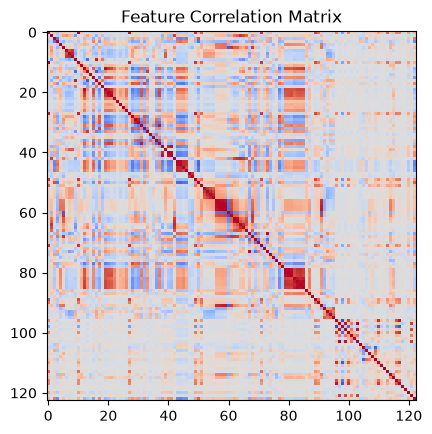

In [38]:
my_correlation_matrix = new_df.corr()
plt.imshow(my_correlation_matrix,cmap="coolwarm")
plt.title("Feature Correlation Matrix")
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [39]:
my_coefficient = new_df.std() / new_df.mean()
print(my_coefficient)

population             2.203503
householdsize          0.353298
racepctblack           1.410920
racePctWhite           0.323782
racePctAsian           1.359162
                         ...   
LemasPctPolicOnPatr    0.122331
LemasGangUnitDeploy    0.368040
LemasPctOfficDrugUn    2.555266
PolicBudgPerPop        0.337281
ViolentCrimesPerPop    0.979015
Length: 123, dtype: float64


### (e) Scatter plots and box plots for highest CV features

Top Features by CV:  ['NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'numbUrban', 'HousVacant', 'LandArea', 'racePctHisp']


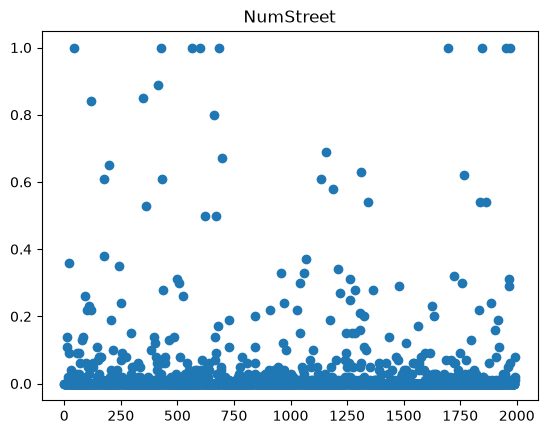

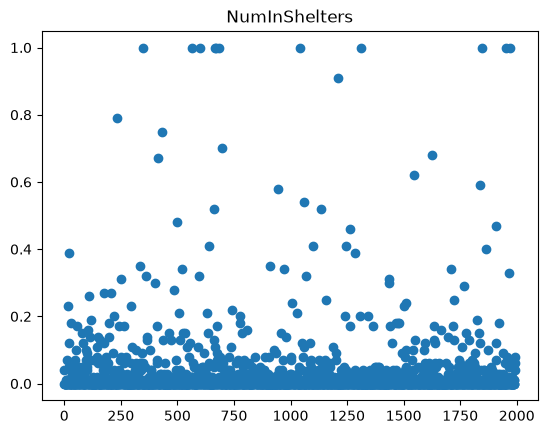

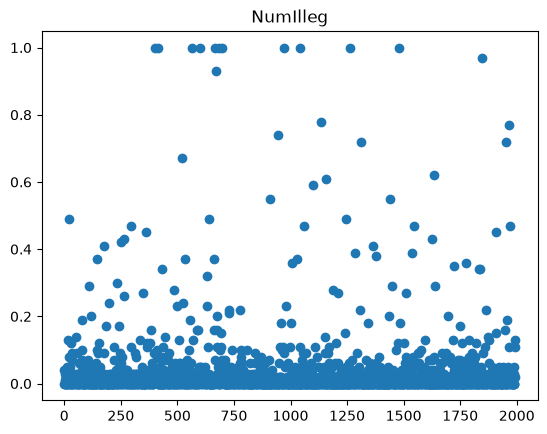

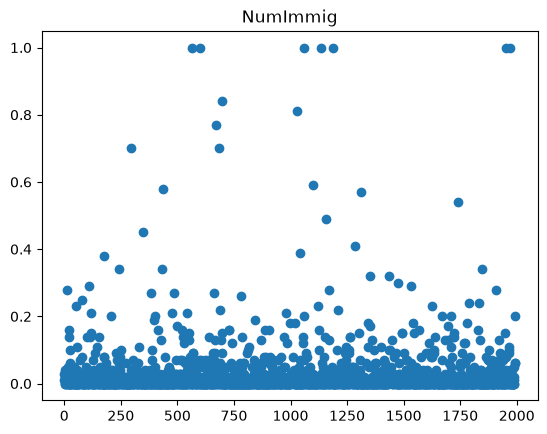

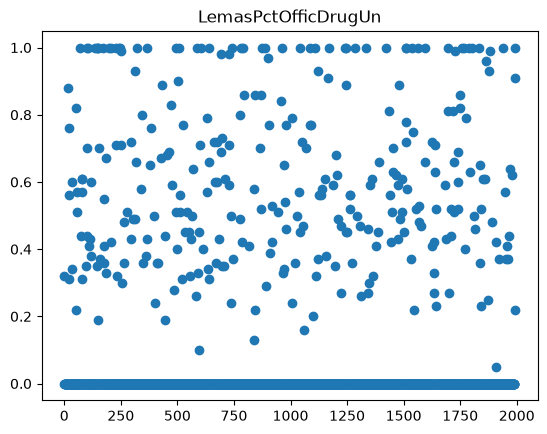

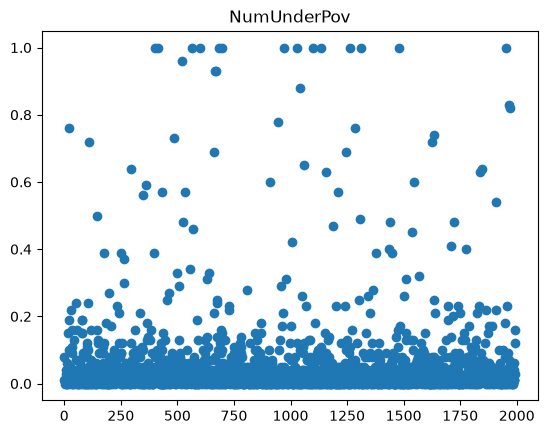

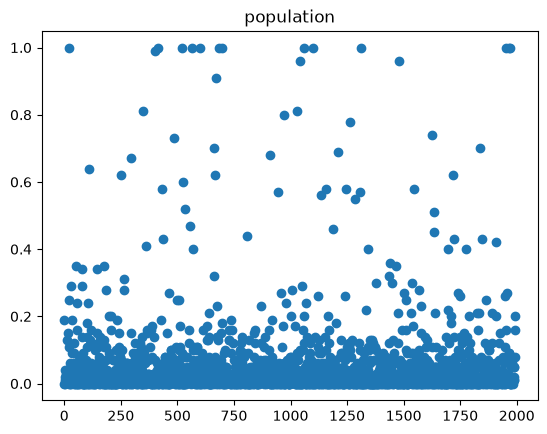

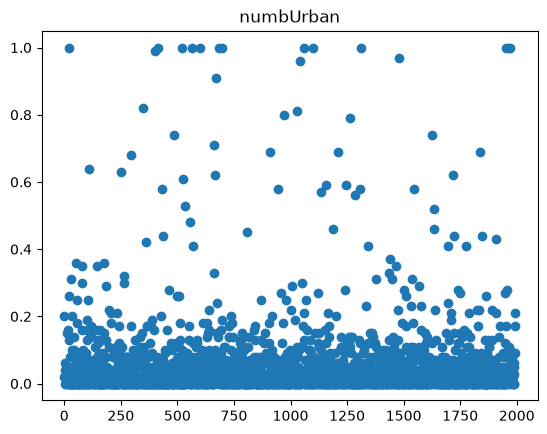

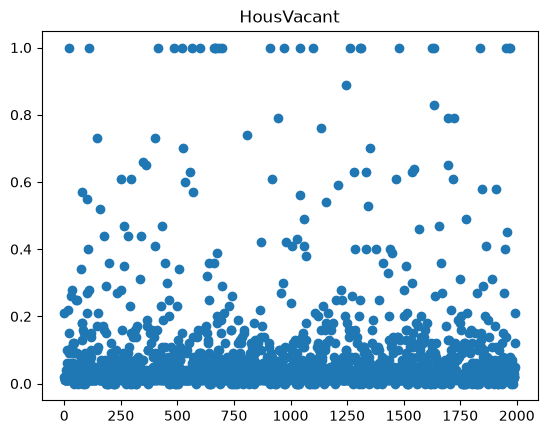

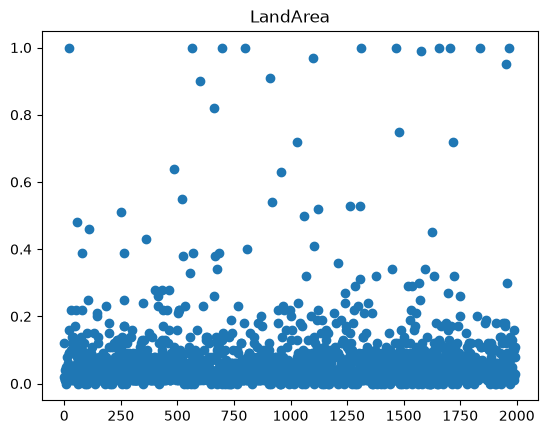

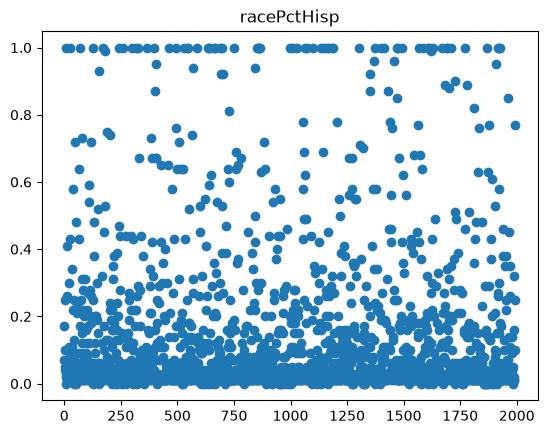

In [43]:
import matplotlib.pyplot as plt
req_param = int(np.floor(np.sqrt(128)))
top_feats = my_coefficient.sort_values(ascending = False).head(req_param).index.tolist()
print("Top Features by CV: ", top_feats)

#printing the scatter plot
for f in top_feats:
    plt.title(f)
    plt.scatter(new_df.index, new_df[f])
    plt.show()

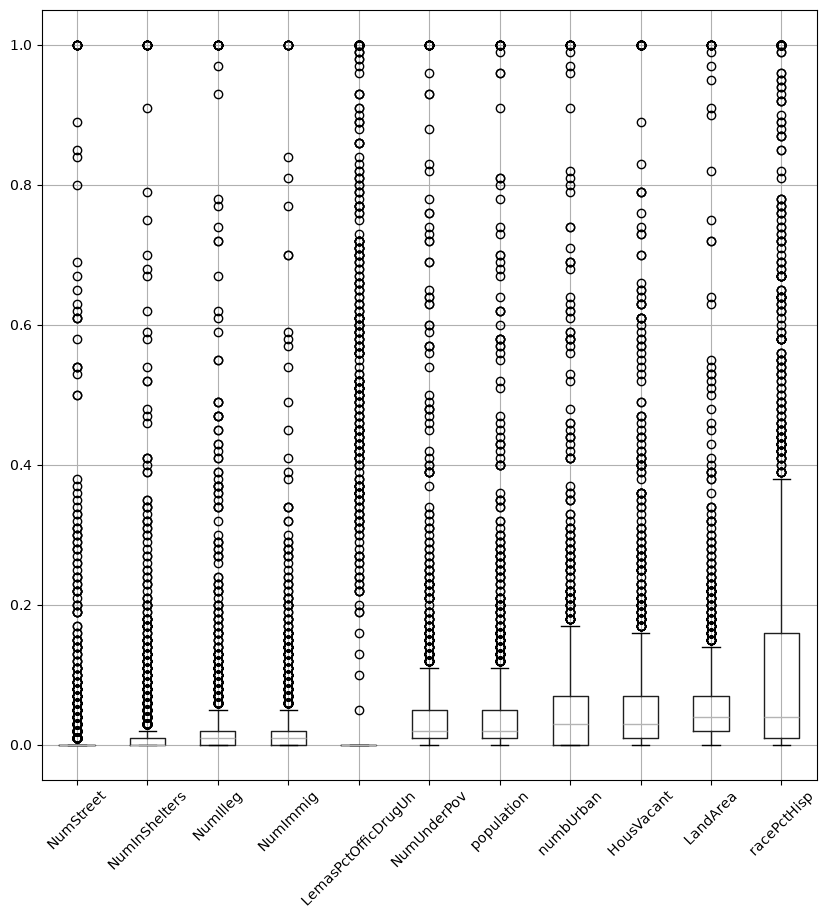

In [45]:
#Printing a box plot for this data
new_df[top_feats].boxplot(figsize = (10,10), rot = 45)
plt.show()

No, you cannot really draw conclusions about the features based on the scatterplot because the scatterplot is not able to accurately define any trends or show any relationship. 

### (f) Fit a linear model

In [53]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error

#creating target and feature dataframes
x = new_df.drop(columns = "ViolentCrimesPerPop")
y = new_df["ViolentCrimesPerPop"]

#Creating the train-test split
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size = 0.3, random_state = 42)

#creating the linear regression model
lin_model = LinearRegression()
lin_model.fit(x_train,y_train)

#getting the prediction values
y_prediction = lin_model.predict(x_test)

#computing test errors
mse = mean_squared_error(y_test,y_prediction)
rmse = np.sqrt(mse)

#Printing test errors
print(f"The test MSE: {mse:.2f}")
print(f"The test RMSE: {rmse:.2f}")



The test MSE: 2.28
The test RMSE: 1.51


### (g) Fit a ridge regression model

In [52]:
#getting the alpha values
alpha = np.logspace(-4,4,100)

my_ridge = GridSearchCV(estimator = Ridge(),param_grid = {"alpha": alpha}, scoring = "neg_mean_squared_error",cv = 5, n_jobs = -1)
my_ridge.fit(x_train,y_train)

#Printing the test error
ry_prediction = my_ridge.predict(x_test)
test_mse = mean_squared_error(y_test,ry_prediction)
r_rmse = np.sqrt(test_mse)

print(f"The Test MSE: {test_mse:.2f}")
print(f"The test RMSE: {r_rmse:.2f}")


The Test MSE: 0.02
The test RMSE: 0.13


### (h) Fit a LASSO model

In [60]:
alpha = np.logspace(-4,4,100)
lasso_search = GridSearchCV(Lasso(max_iter = 1000),param_grid = {"alpha": alpha}, scoring = "neg_mean_squared_error",cv = 5, n_jobs = -1)
lasso_search.fit(x_train,y_train)

lasso_estimator = lasso_search.best_estimator_

raw_ypred = lasso_estimator.predict(x_test)
mse = mean_squared_error(y_test,raw_ypred)
rmse = np.sqrt(mse)

raw_var_coefficients = pd.Series(lasso_estimator.coef_, index = x_train.columns)
selected_vars = raw_var_coefficients[raw_var_coefficients != 0].sort_values(key = abs, ascending = False)

#Printing the test error and list of variables
print(f"Raw test MSE: {mse:.2f}")
print(f"Raw RMSE: {rmse:.2f}")
print("\n")

print("Selected Variables: ")
print(selected_vars.to_string())


Raw test MSE: 0.02
Raw RMSE: 0.13


Selected Variables: 
NumStreet                0.223765
racepctblack             0.192153
PctIlleg                 0.178125
RentLowQ                -0.176843
MedRent                  0.169312
pctWInvInc              -0.136815
PctYoungKids2Par        -0.133921
MalePctDivorce           0.128706
PctKids2Par             -0.108823
HousVacant               0.105298
PctPopUnderPov          -0.100465
MedOwnCostPctIncNoMtg   -0.099226
PctWorkMom              -0.089355
NumIlleg                -0.081288
PctHousOccup            -0.064539
PctRecImmig8             0.057229
PctLess9thGrade         -0.053586
RacialMatchCommPol      -0.052889
pctWSocSec               0.051748
PolicReqPerOffic         0.050172
MedRentPctHousInc        0.050021
PctHousNoPhone           0.049075
pctWRetire              -0.047200
PctEmplManu             -0.047155
whitePerCap             -0.045195
PctPersDenseHous         0.044138
PctUnemployed           -0.042262
PctVacantBoarded         

In [69]:
from sklearn.pipeline import make_pipeline
#Using Standard Features
std_lasso_model = GridSearchCV(make_pipeline(StandardScaler(), Lasso(max_iter = 1000)),param_grid = {"lasso__alpha": alpha}, scoring = "neg_mean_squared_error",cv = 5, n_jobs = -1)
std_lasso_model.fit(x_train,y_train)

#Prediction Values
std_best_estimator = std_lasso_model.best_estimator_
std_ypred = std_lasso_model.predict(x_test)

std_mse = mean_squared_error(y_test,std_ypred)
std_rmse = np.sqrt(std_mse)
raw_var_coefficients = pd.Series(std_best_estimator.named_steps["lasso"].coef_, index = x_train.columns)
selected_vars = raw_var_coefficients[raw_var_coefficients != 0].sort_values(key = abs, ascending = False)

print(f"The test MSE of Standard Features: {std_mse:.2f}")
print(f"The test RMSE of Standard Features: {std_rmse:.2f}")
print("\n")
print("Selected Variables: ")
print(selected_vars.to_string())


The test MSE of Standard Features: 0.02
The test RMSE of Standard Features: 0.13


Selected Variables: 
PctIlleg                 0.045894
PctKids2Par             -0.038325
racepctblack             0.032153
MalePctDivorce           0.027370
NumStreet                0.021027
racePctWhite            -0.016690
pctUrban                 0.013252
PctYoungKids2Par        -0.012333
PctHousOccup            -0.011995
HousVacant               0.011333
PctPersDenseHous         0.011067
PctForeignBorn           0.010282
PctWorkMom              -0.009435
pctWInvInc              -0.009024
MedOwnCostPctIncNoMtg   -0.007337
AsianPerCap              0.003800
LemasPctOfficDrugUn      0.003599
PctVacantBoarded         0.003487
PolicReqPerOffic         0.003458
RacialMatchCommPol      -0.003395
PctEmplManu             -0.003374
MedRentPctHousInc        0.003035
PctPolicWhite           -0.000958
agePct12t29             -0.000904
PctPolicBlack            0.000639
HispPerCap               0.000536
OtherPerCap 

### (i) Fit a PCR model

In [70]:
from sklearn.decomposition import PCA
max_m = min(x_train.shape)
m_vals = list(range(1,max_m + 1))

my_pcr = make_pipeline(StandardScaler(),PCA(),LinearRegression())

pcr_search = GridSearchCV(my_pcr,param_grid={"pca__n_components" : m_vals}, scoring = "neg_mean_squared_error", cv = 5, n_jobs = -1)
pcr_search.fit(x_train,y_train)

best_m = pcr_search.best_params_["pca__n_components"]
ypred = pcr_search.predict(x_test)
mse = mean_squared_error(y_test,ypred)
rmse = np.sqrt(mse)

print(f"The best M: {best_m}")
print(f"The Test MSE: {mse:.2f}")
print(f"The test RMSE: {rmse:.2f}")



The best M: 73
The Test MSE: 0.02
The test RMSE: 0.14


### (j) Fit a boosting tree

In [74]:
import xgboost as xgb
x_model = xgb.XGBRegressor(objective = "reg:squarederror",random_state = 42, n_jobs = -1)
param_grid = {"reg_alpha":alpha}

tree_search = GridSearchCV(estimator = x_model,param_grid=param_grid,scoring = "neg_mean_squared_error",cv = 5, n_jobs = -1)
tree_search.fit(x_train,y_train)

best_alpha = tree_search.best_params_["reg_alpha"]

tree_ypred = tree_search.predict(x_test)
mse = mean_squared_error(y_test, tree_ypred)
rmse = np.sqrt(mse)

print(f"The best alpha: {best_alpha :.2f}")
print(f"The Test MSE: {mse:.2f}")
print(f"The Test RMSE: {rmse:.2f}")


The best alpha: 0.76
The Test MSE: 0.02
The Test RMSE: 0.14
